# Stat 220, Unit 5 Homework: When a Line Is Not Enough

`rent.csv` is 4,743 rental listings from six Indian cities. `Rent` is the monthly
rent in rupees. The predictors are `Size` (square feet), `BHK` (bedrooms), `Bathroom`, `City`,
and `FurnishingStatus`. Rent runs from Rs 1,200 to Rs 3,500,000 a month.

Run the next two cells first. The first installs what you need, and the second loads the data
everything else uses.

In [1]:
%pip install -q numpy pandas statsmodels scikit-learn matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.model_selection import train_test_split

rent = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/rent.csv")
RHS = "BHK + Bathroom + C(City) + C(FurnishingStatus)"
rent.head()

,BHK,Rent,Size,AreaType,City,FurnishingStatus,Preferred,Bathroom,Contact
0,2,10000,1100,Super Area,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2,20000,800,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2,17000,1000,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2,10000,800,Super Area,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2,7500,850,Carpet Area,Kolkata,Unfurnished,Bachelors,1,Contact Owner


**Problem 1.** *Is the line in trouble?* Fit rent on the predictors as they come.

Part a. Report the $R^2$ and the fan ratio, and paste the residual plot. The fan ratio is the spread of the residuals on the high half of the fitted values over the spread on the low half; 1 means even.

R2: 0.313   fan ratio: 4.9


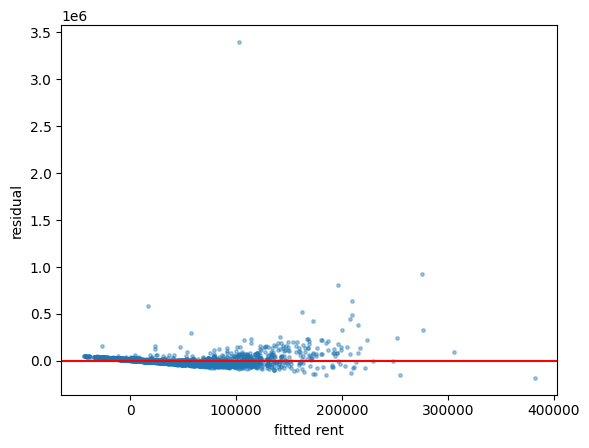

In [3]:
plain = smf.ols(f"Rent ~ Size + {RHS}", data=rent).fit()

r = pd.DataFrame({"fitted": plain.fittedvalues, "resid": plain.resid})
fan = r[r.fitted >= r.fitted.median()].resid.std() / r[r.fitted < r.fitted.median()].resid.std()
print("R2:", round(plain.rsquared, 3), "  fan ratio:", round(fan, 2))

plt.scatter(plain.fittedvalues, plain.resid, s=6, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("fitted rent"); plt.ylabel("residual");

_Your answer:_ R^2 value is low at 0.313 with a fan ratio of 4.9.

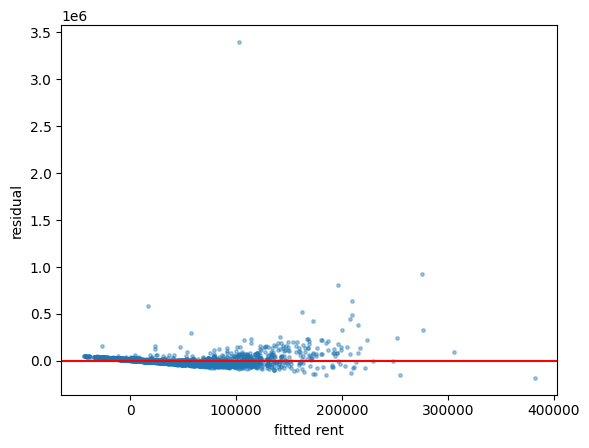


Part b. Name the two things wrong with this residual plot, and say what each one does to the predictions.

_Your answer:_ Aside from the low R^2 value, this residual plot has a pattern in it's shape which causes us to question our assumption of linearity, this means that predictions cannot be accurately made using this model. Additionally, the spread of the residuals is very uneven from the high end to the low end as shown by our high fan ratio (4.9), so RMSE would be unreliable given the spread from low end to high end.



**Problem 2.** *The fix.* Log both sides and look again.

Part a. Report the $R^2$ and the fan ratio for the logged model, next to the ones from problem 1.

R2: 0.77   fan ratio: 1.31
coefficient on log(Size): 0.263


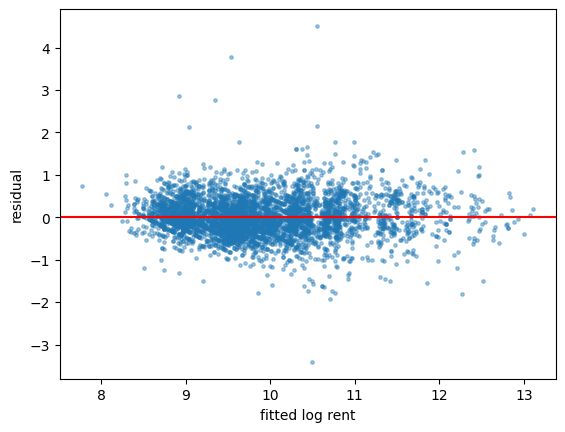

In [4]:
logged = smf.ols(f"np.log(Rent) ~ np.log(Size) + {RHS}", data=rent).fit()

r = pd.DataFrame({"fitted": logged.fittedvalues, "resid": logged.resid})
fan = r[r.fitted >= r.fitted.median()].resid.std() / r[r.fitted < r.fitted.median()].resid.std()
print("R2:", round(logged.rsquared, 3), "  fan ratio:", round(fan, 2))
print("coefficient on log(Size):", round(logged.params["np.log(Size)"], 3))

plt.scatter(logged.fittedvalues, logged.resid, s=6, alpha=0.4)
plt.axhline(0, color="red")
plt.xlabel("fitted log rent"); plt.ylabel("residual");

_Your answer:_ After logging both sides, our R^2 value is much better at 0.77 than our pre-logged value (0.31) and our fan ratio has dropped from 4.9 to 1.31.

---





Part b. The coefficient on `np.log(Size)` is about 0.26. Write the sentence you would give a renter: what happens to the rent when the apartment is 10% bigger, with everything else the same?

_Your answer:_ When an apartment is 10% bigger, all other predictors being held constant(BHK,BathroomCity,etc.), we can assume that rent prices would rise by about 2.6%.



Part c. The $R^2$ went from problem 1's value to this one. Explain in two sentences why those two numbers cannot be compared directly.

_Your answer:_ The R^2 from problem 1 and R^2 from problem 2 cannot be directly compared because our variables have been logged and the scale of our response variable is now completely different between the two models and not necessarily more practical (in rupee terms) even though log allows us to understand the data better.



**Problem 3.** *A different idea.* Grow a shallow tree on the same columns and read it.

Part a. Print the tree and report its first three splits.

|--- Bathroom <= 2.50
|   |--- City_Mumbai <= 0.50
|   |   |--- Bathroom <= 1.50
|   |   |   |--- value: [9.06]
|   |   |--- Bathroom >  1.50
|   |   |   |--- value: [9.64]
|   |--- City_Mumbai >  0.50
|   |   |--- Size <= 658.00
|   |   |   |--- value: [10.22]
|   |   |--- Size >  658.00
|   |   |   |--- value: [10.96]
|--- Bathroom >  2.50
|   |--- City_Mumbai <= 0.50
|   |   |--- Size <= 2237.50
|   |   |   |--- value: [10.32]
|   |   |--- Size >  2237.50
|   |   |   |--- value: [11.46]
|   |--- City_Mumbai >  0.50
|   |   |--- Size <= 1507.00
|   |   |   |--- value: [11.48]
|   |   |--- Size >  1507.00
|   |   |   |--- value: [12.45]



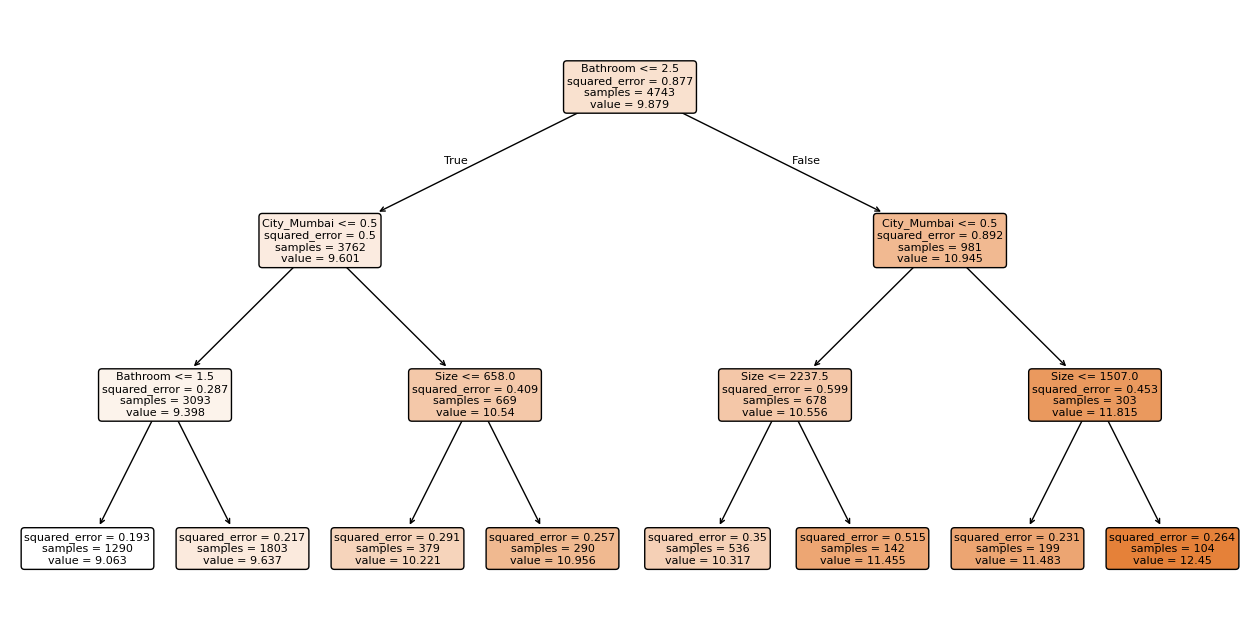

In [6]:
X = pd.get_dummies(rent[["Size", "BHK", "Bathroom", "City", "FurnishingStatus"]],
                   drop_first=True)
y = np.log(rent.Rent)

tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X, y)
print(export_text(tree, feature_names=list(X.columns), decimals=2))

from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=list(X.columns), filled=True, rounded=True, fontsize=8)
plt.show()

_Your answer:_ The first three splits of this tree are bathroom <= 2.5 (split one), City_mumbai <=0.5 (split 2), and sizes <= 658.0, <= 2237.5, <= 1507.0 and bathroom <=1.5 (split 3).



Part b. Describe the kind of listing that lands in the most expensive leaf, and the kind that lands in the cheapest.

_Your answer:_ The most expensive listings have more than 2.5 bathrooms, are in Mumbai, and are larger than 1507 square feet. The cheapest listings are not in Mumbai and have less than 1.5 bathrooms.



Part c. The tree never splits on `FurnishingStatus`. Does that mean furnishing has no effect on rent? Explain.

_Your answer:_ Although the tree never splits on FurnishingStatus that does not mean that furnishing has no effect on rent, it means that it has less of an effect than the other predictors shown, or that it may have a correlation with other predictors.



**Problem 4.** *How deep should it go?*

Part a. Report the table, and say which depth you would use.

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)

for depth in [1, 2, 4, 6, 8, 10, 12]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xtr, ytr)
    own = np.sqrt(((ytr - t.predict(Xtr))**2).mean())
    held = np.sqrt(((yte - t.predict(Xte))**2).mean())
    print(f"depth {depth:>2}   own rows {own:.3f}   held back {held:.3f}")

depth  1   own rows 0.759   held back 0.770
depth  2   own rows 0.597   held back 0.605
depth  4   own rows 0.461   held back 0.475
depth  6   own rows 0.405   held back 0.451
depth  8   own rows 0.366   held back 0.457
depth 10   own rows 0.319   held back 0.476
depth 12   own rows 0.282   held back 0.487


_Your answer:_ The table shows potential depths for a regression tree with "own rows" showing the RMSE for the rows we built the model on and "held back" showing the rows that were kept out for testing. In this case we should use a depth of 6 because that has the lowest RMSE for new data.



Part b. One column falls all the way down and the other turns around. Explain what each column is measuring and why only one of them can choose the depth.

_Your answer:_ Each column is measuring the average prediction error in the model being used, the difference being that "own rows" shows what the model was trained on and "held back" simulates new data. We can only use the "held back" values because "own rows" will decrease naturally as the model fits the trained data better and better, but might become too rigid for new real data.



**Problem 5.** *Let the tree inform the regression.* The tree splits on Mumbai, and then uses
a different `Size` cut inside the Mumbai branch than outside it.

Part a. Report the interaction coefficient, its p-value, and the AIC of both models.

In [8]:
rent["mumbai"] = (rent.City == "Mumbai").astype(int)
inter = smf.ols(f"np.log(Rent) ~ np.log(Size) + np.log(Size):mumbai + {RHS}", data=rent).fit()

b = inter.params["np.log(Size)"]
extra = inter.params["np.log(Size):mumbai"]
print("elasticity outside Mumbai:", round(b, 3))
print("elasticity in Mumbai     :", round(b + extra, 3))
print("p-value on the interaction:", format(inter.pvalues["np.log(Size):mumbai"], ".2g"))
print("AIC:", round(logged.aic), "->", round(inter.aic))

elasticity outside Mumbai: 0.259
elasticity in Mumbai     : 0.513
p-value on the interaction: 1.5e-16
AIC: 5889 -> 5822


_Your answer:_ The coefficient for np.log(size) and rent price for properties outside of Mumbai (0.259) are smaller than for properties in Mumbai (0.513), with AIC decreasing from 5889 to 5822 as the model is focused on Mumbai specifically. From our data we can assume that the probability of seeing this data with no interaction would be less than 1 percent(p-value < 0.001).



Part b. Write three or four sentences a property manager could use. Give the number, the units, what is being held fixed, and what they should do about it.

_Your answer:_ When an apartment is 10% bigger, all other predictors being held constant(number of bedrooms, bathrooms, furnishings, etc.), we can assume that rent prices would rise by about 2.6%. However, in Mumbai, for a similar size increase of 10%, and holding the same variables constant, we would estimate that rent prices would rise by around 5.1%. This means that increasing unit size will likely pay off more in Mumbai than in other cities and they should probably invest more there.



Part c. A colleague says this proves that building bigger apartments in Mumbai causes higher rent per square foot. Explain why that is more than these listings can show, and say what they do show.

_Your answer:_ These listings cannot show definitively that building bigger apartments in Mumbai would cause higher rent per square foot because there may be unaccounted-for correlations between Mumbai and other predictors that have not yet been identified. What this can tell us is that there is an interaction between higher prices with larger units in Mumbai.

